# Milan: categorical attrition analysis

This notebook demonstrates within-group rates and the seven categorical figure files. Each percentage has its own group denominator. Statistical tests and numeric plots belong to Rudra's portion.

In [1]:
from pathlib import Path
import sys
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Open this notebook from the repository or notebooks folder.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data import RAW_NAME, prepare, group_rates
raw_path = ROOT / 'data' / 'raw' / RAW_NAME

clean, audit = prepare(raw_path)


## 1. Build an overtime rate table

`groupby` separates categories. `size` counts group employees, and `sum` counts leavers from the 0/1 flag. `rate_pct` is 100 times leavers divided by employees in that group.

In [2]:
overtime = group_rates(clean, 'OverTime')
overtime

,OverTime,n,left,rate_pct,small_group
0,No,1054,110,10.436433,False
1,Yes,416,127,30.528846,False


## 2. Independently verify the denominator

Here the manual calculation uses just overtime workers. Using all 1,470 employees as the denominator would answer a different question.

In [3]:
workers = clean.loc[clean.OverTime == 'Yes']
manual = 100 * workers.AttritionFlag.sum() / len(workers)
computed = overtime.set_index('OverTime').loc['Yes', 'rate_pct']
assert abs(manual - computed) < 1e-10
print(f'Overtime: {int(workers.AttritionFlag.sum())}/{len(workers)} = {computed:.2f}%')
rates = overtime.set_index('OverTime').rate_pct
print(f'Difference: {rates["Yes"]-rates["No"]:.2f} percentage points')

Overtime: 127/416 = 30.53%
Difference: 20.09 percentage points


## 3. Check age groups and small samples

The n<30 marker is a descriptive caution flag, not a statistical guarantee. Compare percentages alongside the counts.

In [4]:
group_rates(clean, 'AgeGroup')

,AgeGroup,n,left,rate_pct,small_group
0,18-29,326,91,27.914110,False
1,30-39,622,89,14.308682,False
2,40-49,349,34,9.742120,False
3,50+,173,23,13.294798,False


## 4. Generate only Milan's figures

The categorical module returns exactly the seven files it generates. It leaves existing numeric figures alone. Figures 03 and 07 contain multiple panels.

01_attrition_distribution.png


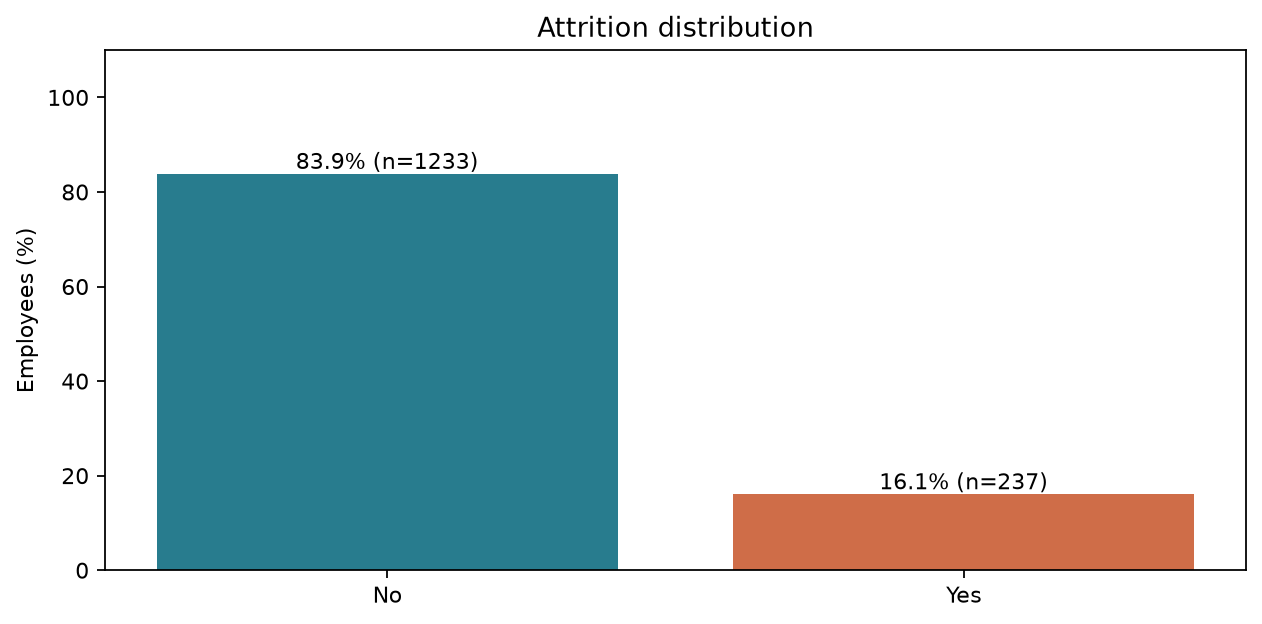

02_overtime.png


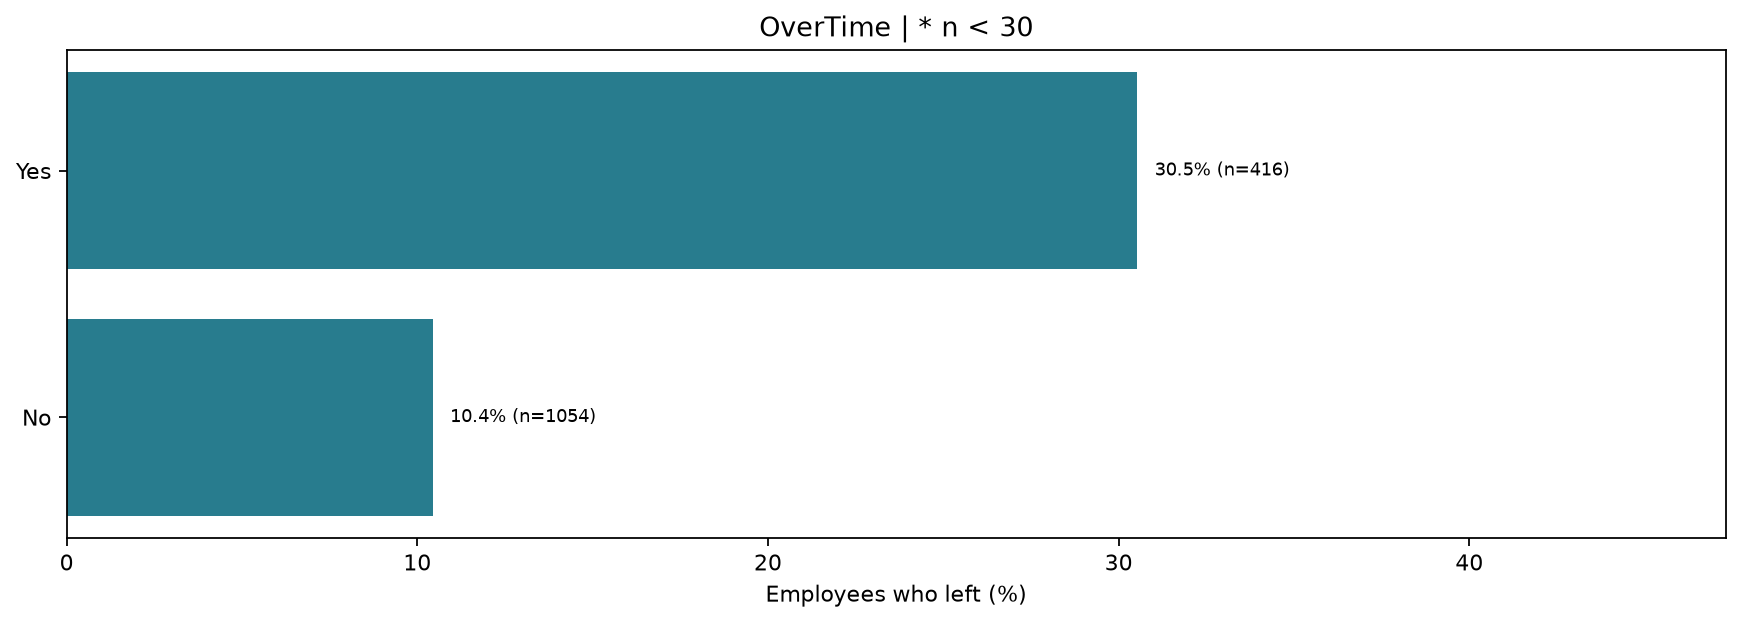

03_department_jobrole.png


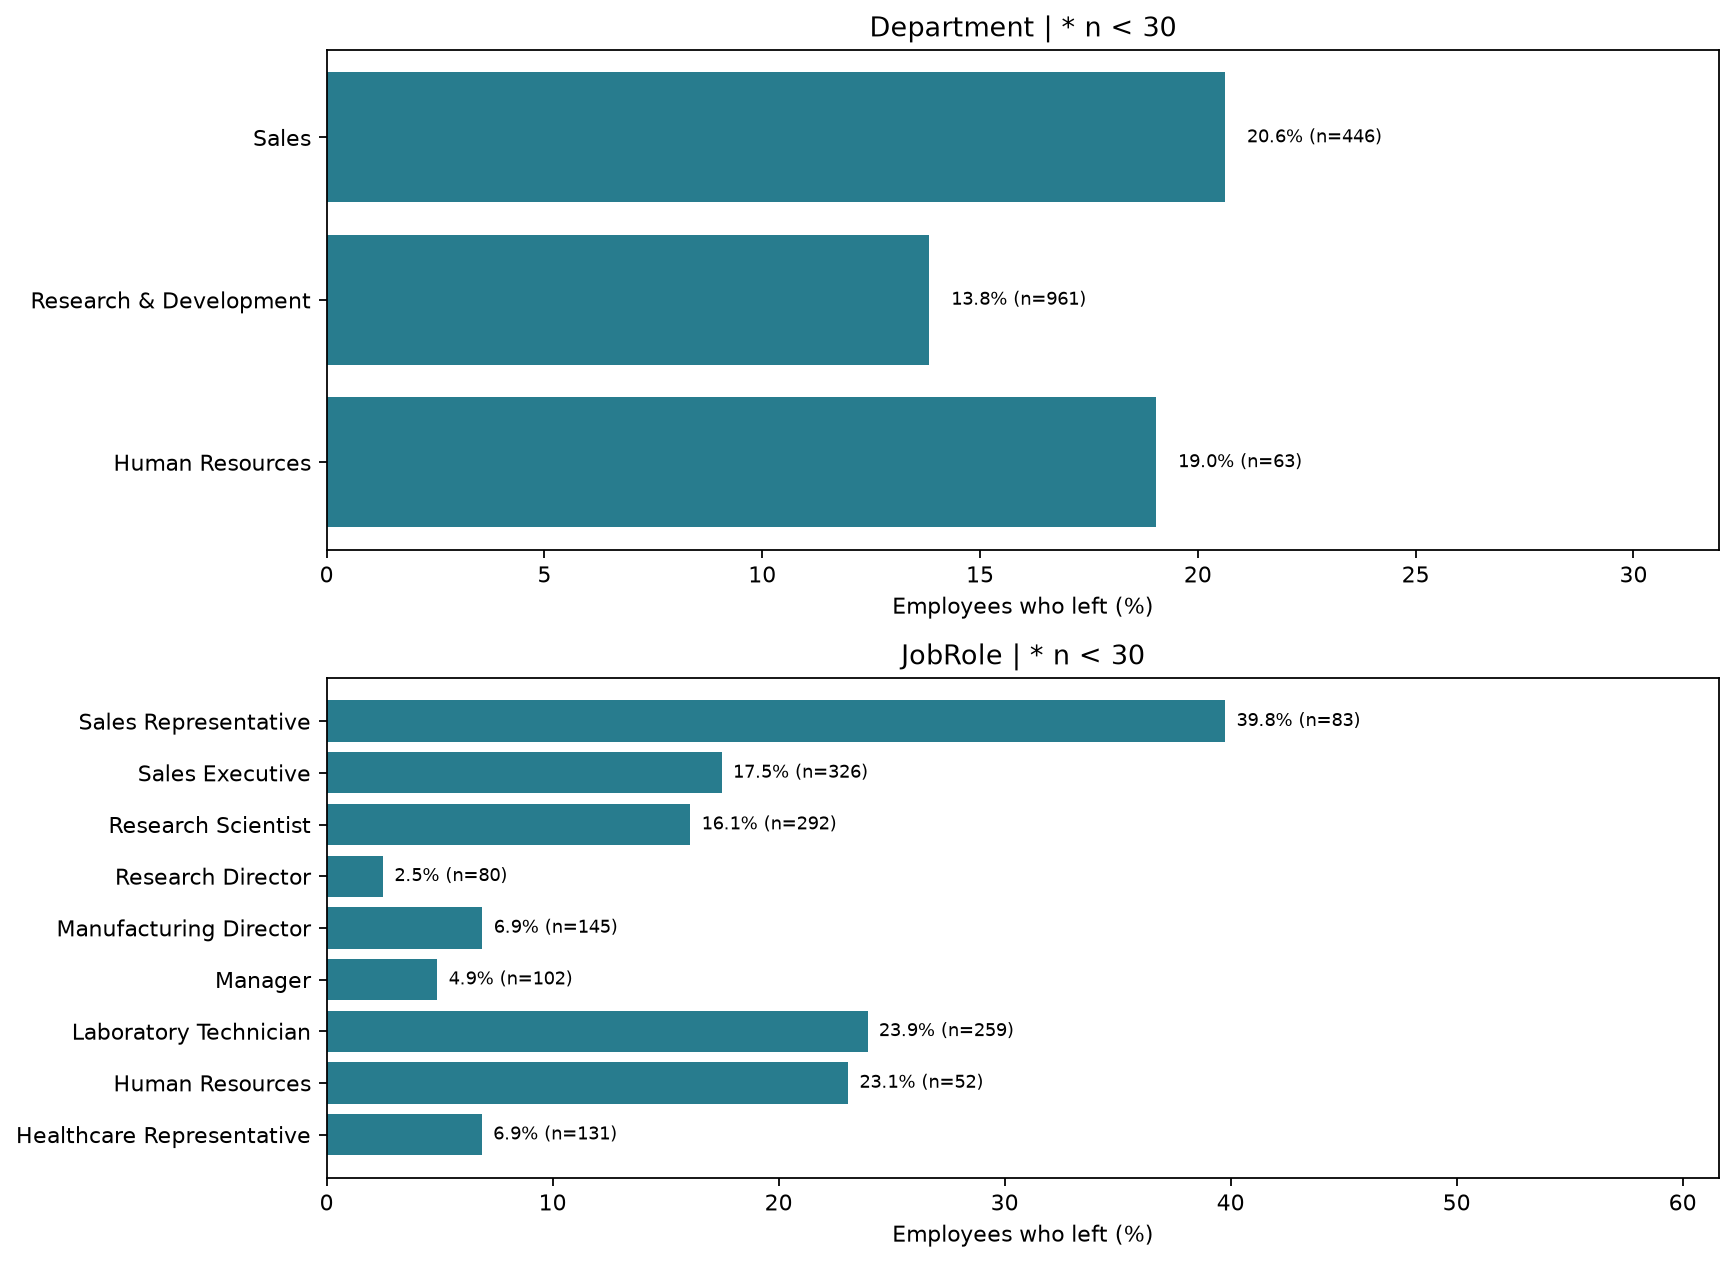

04_age_groups.png


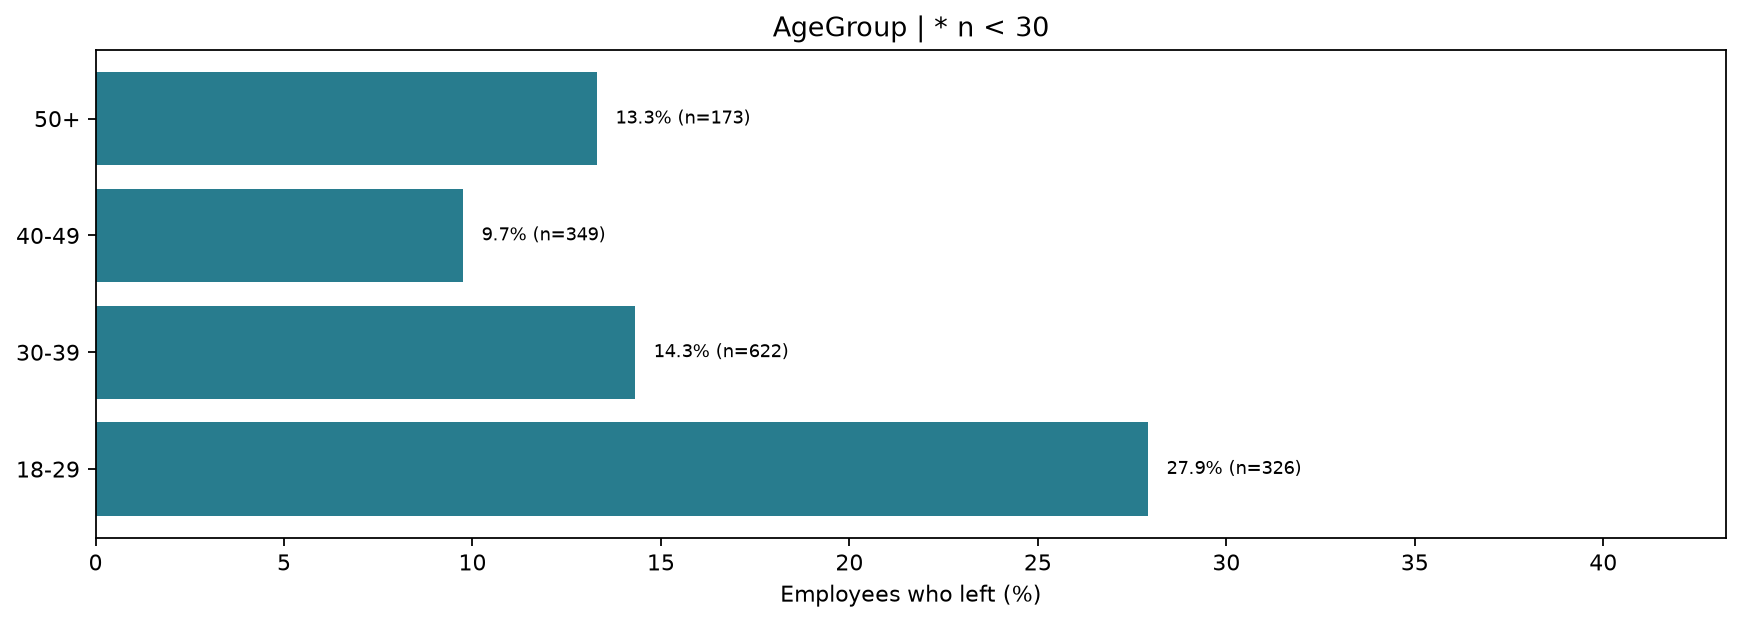

06_job_level.png


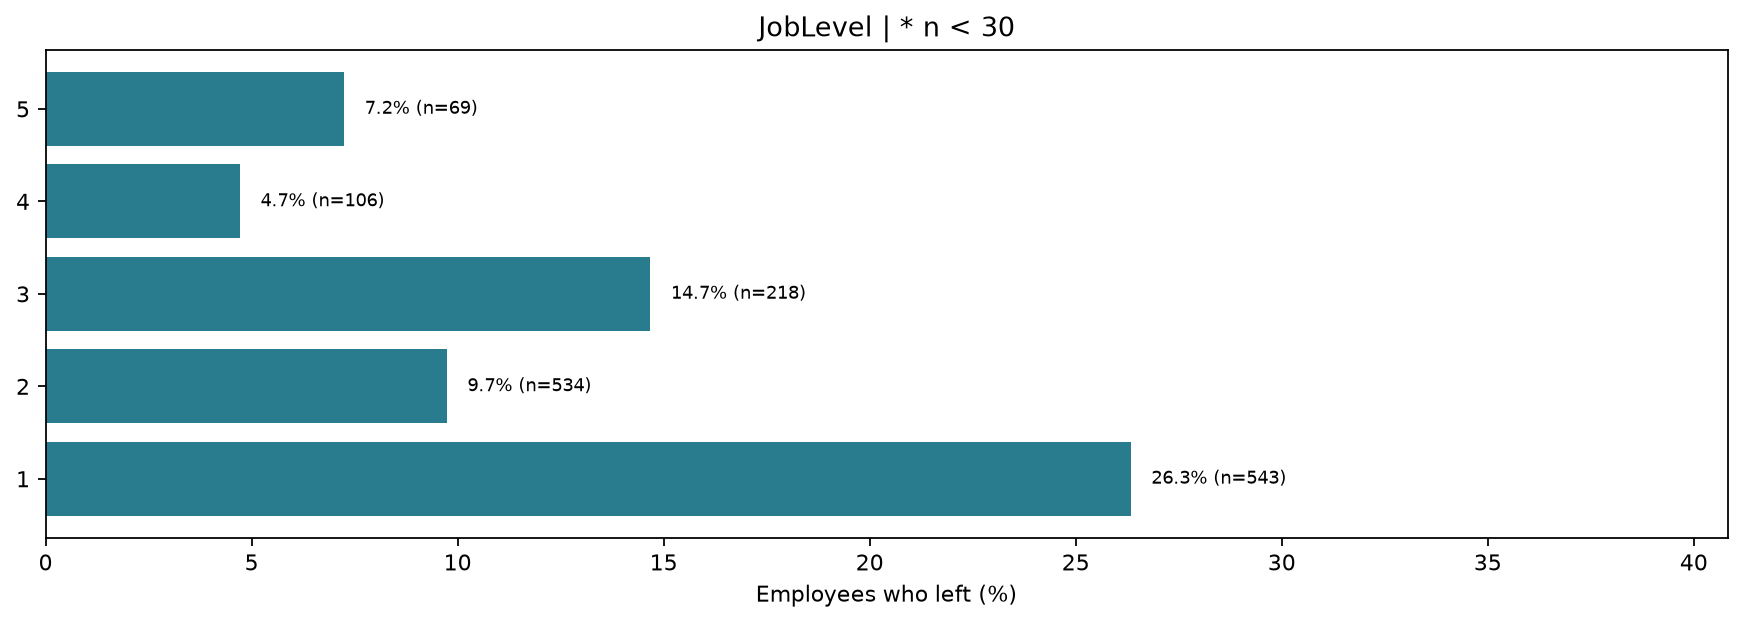

07_satisfaction.png


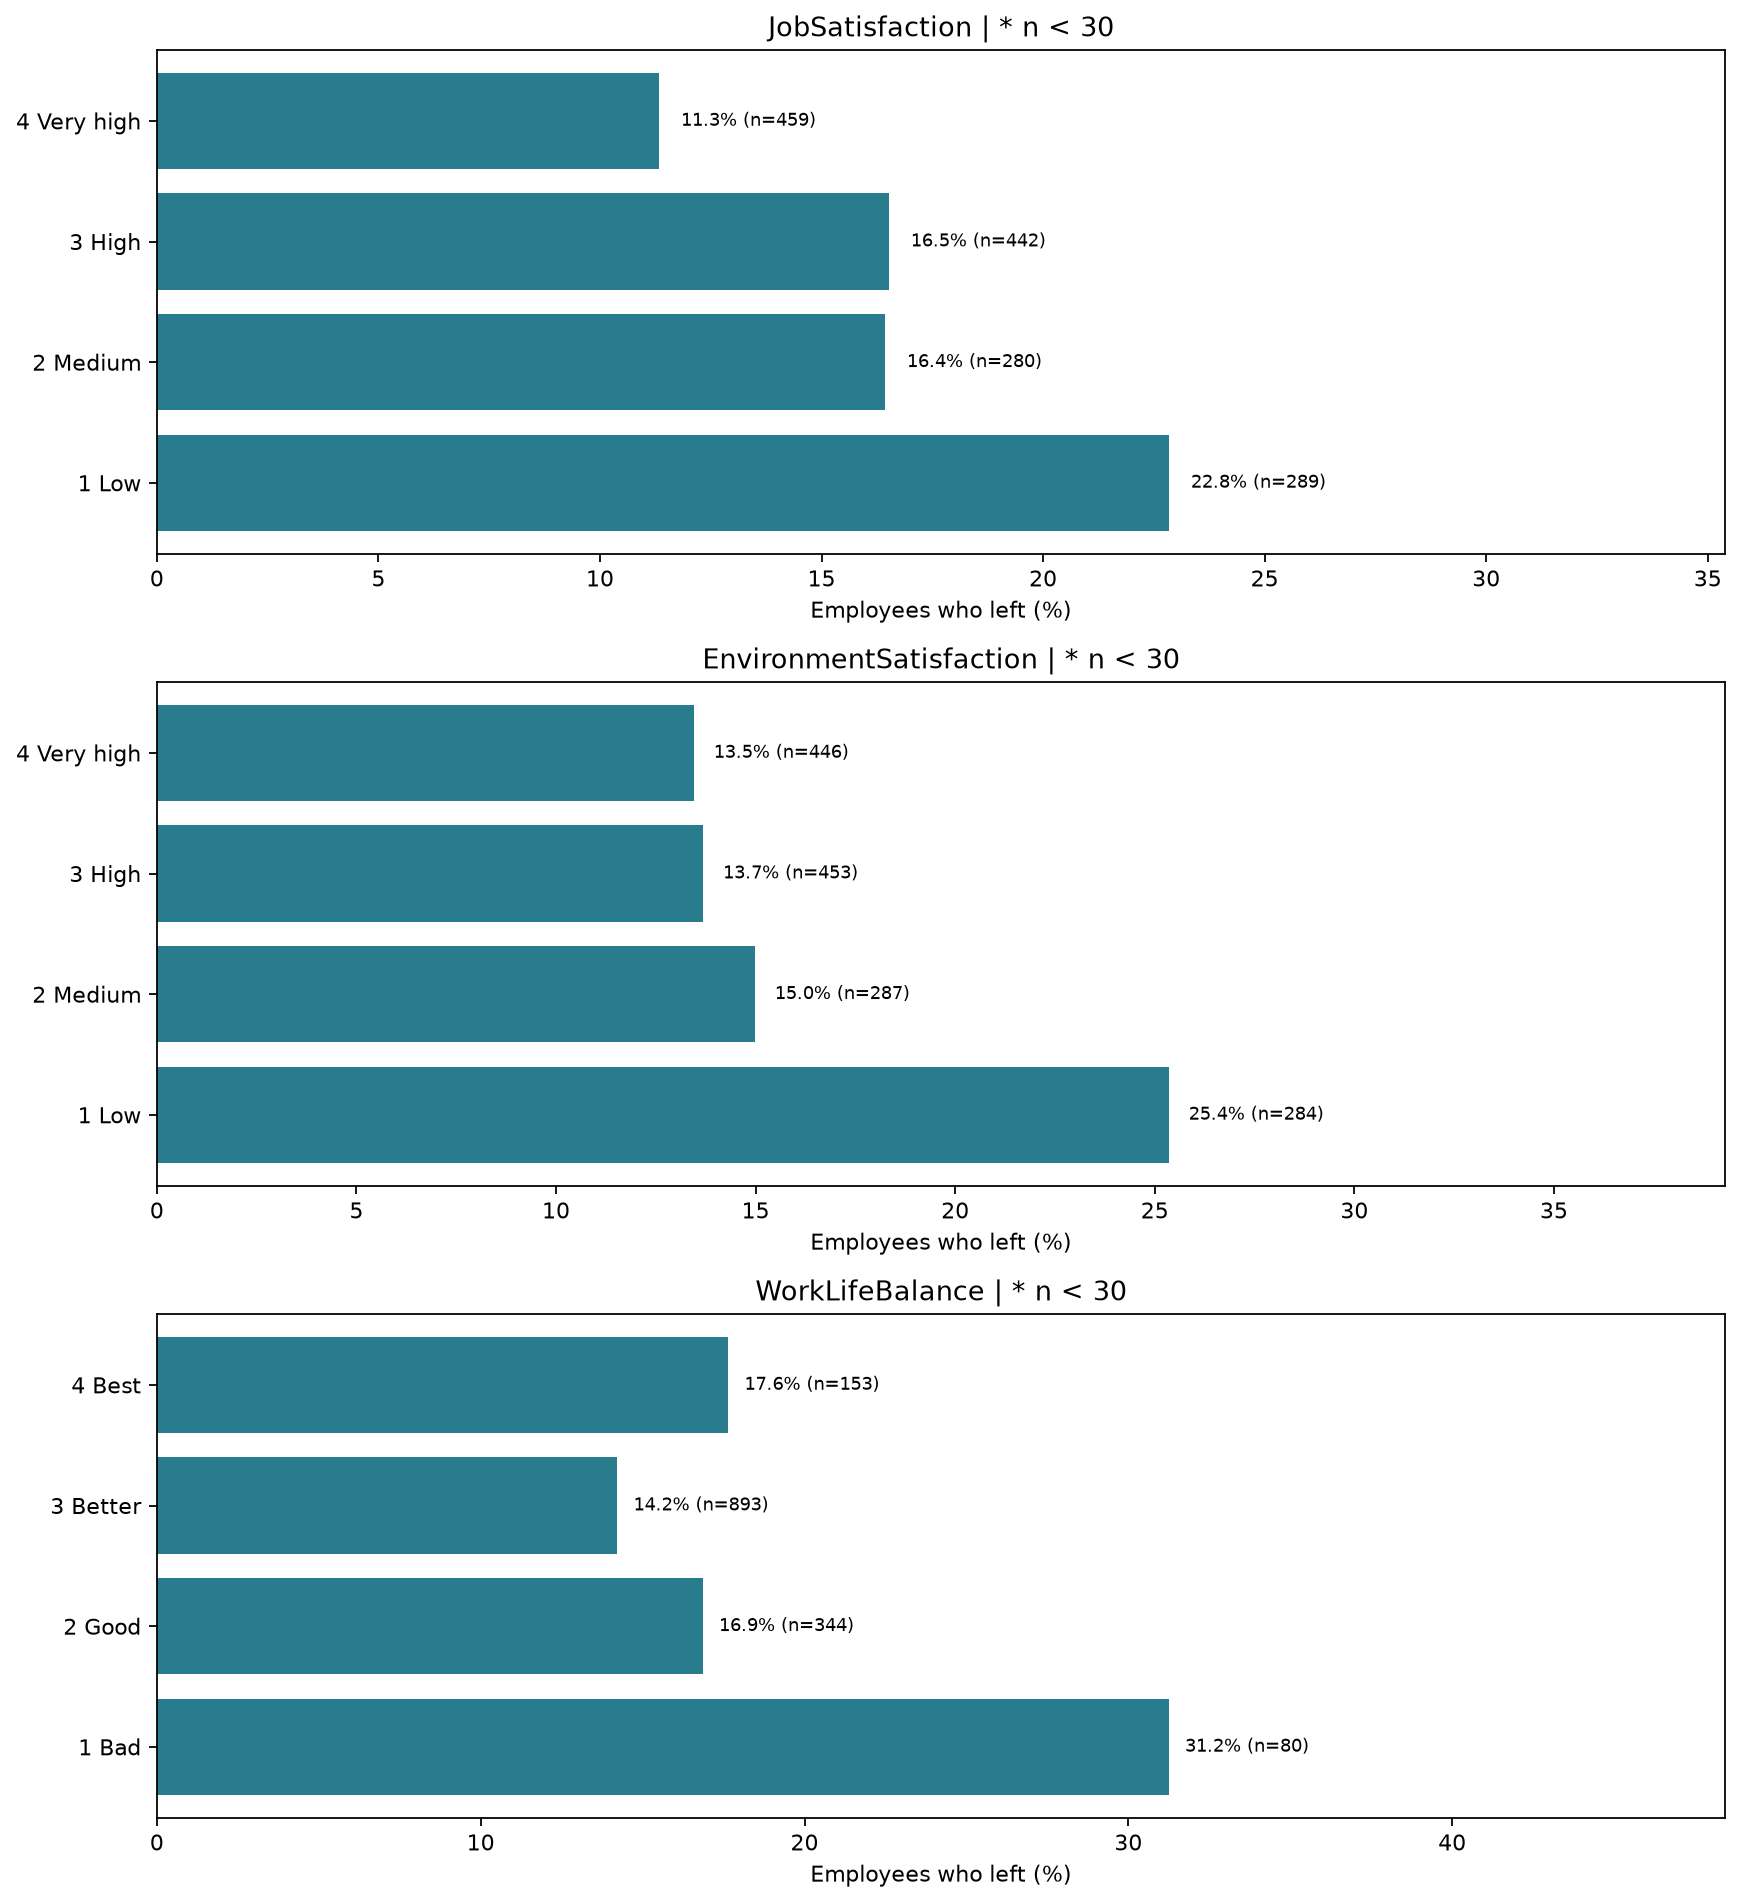

10_business_travel.png


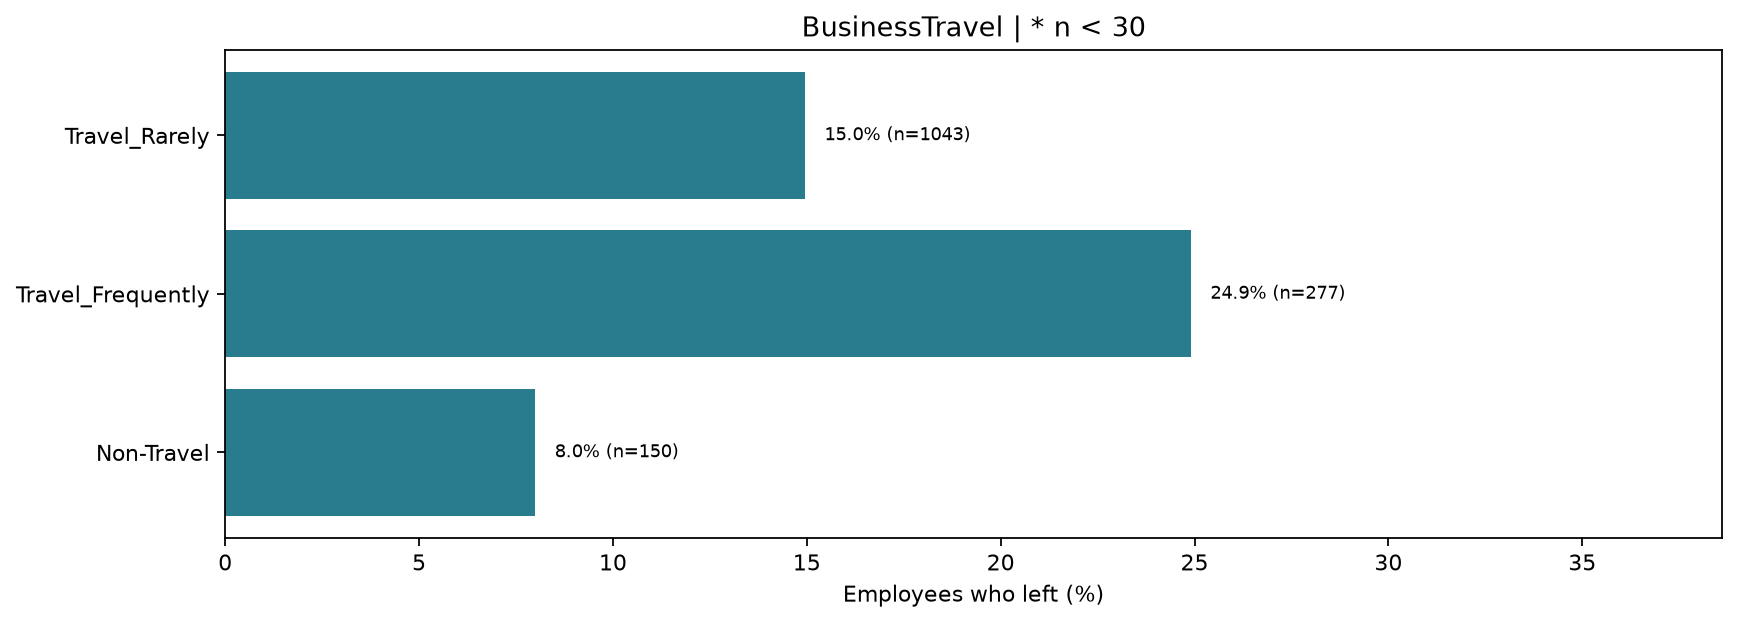

In [5]:
from src.categorical import categorical_plots
from IPython.display import display, Image
paths = categorical_plots(clean, ROOT / 'visualizations')
assert len(paths) == 7
for path in paths:
    print(path.name)
    display(Image(filename=str(path)))

## Interpretation for discussion

Overtime workers show 30.53% attrition versus 10.44% without overtime, a gap of 20.09 percentage points. Ages 18-29 show 27.91% versus 9.74% for ages 40-49. These are descriptive associations within a fictional dataset. The comparison does not control for other characteristics and does not establish causes. The independent runner exports all nine group tables to `reports/` and writes `reports/milan_results.md`.